## Deep Exploratory analysis , Feature Engineering & Baseline Modeling 

## Load the dataset and examine its structure

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Steel_industry_data.csv')

In [3]:
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


In [4]:
## Convert the date column to datetime and extract: hour of day, day of week, month, and whether
## the day is a weekday or weekend — add these as new columns.

In [5]:


df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M')


df['hour'] = df['date'].dt.hour


df['day_of_week'] = df['date'].dt.day_name()


df['month'] = df['date'].dt.month

df['is_weekend'] = df['date'].dt.dayofweek >= 5   
df['is_weekend'] = df['is_weekend'].map({True: 'Weekend', False: 'Weekday'})

df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,hour,day_of_week,month,is_weekend
0,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,0,Monday,1,Weekday
1,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,0,Monday,1,Weekday
2,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,0,Monday,1,Weekday
3,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,1,Monday,1,Weekday
4,2018-01-01 01:15:00,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load,1,Monday,1,Weekday


In [6]:
df['Power_Factor_Ratio'] = df['Leading_Current_Power_Factor'] / df['Lagging_Current_Power_Factor']


In [7]:
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,hour,day_of_week,month,is_weekend,Power_Factor_Ratio
0,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,0,Monday,1,Weekday,1.365934
1,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,0,Monday,1,Weekday,1.497679
2,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,0,Monday,1,Weekday,1.422880
3,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,1,Monday,1,Weekday,1.468644
4,2018-01-01 01:15:00,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load,1,Monday,1,Weekday,1.545117


In [8]:
threshold = df['Usage_kWh'].quantile(0.75)

df['High_Load'] = (df['Usage_kWh'] > threshold).astype(int)

In [9]:
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,hour,day_of_week,month,is_weekend,Power_Factor_Ratio,High_Load
0,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,0,Monday,1,Weekday,1.365934,0
1,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,0,Monday,1,Weekday,1.497679,0
2,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,0,Monday,1,Weekday,1.422880,0
3,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,1,Monday,1,Weekday,1.468644,0
4,2018-01-01 01:15:00,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load,1,Monday,1,Weekday,1.545117,0


In [10]:
df['High_Load'].value_counts()

High_Load
0    26280
1     8760
Name: count, dtype: int64

Q1: 3.2, Q3: 51.2375, IQR: 48.037499999999994
Lower bound: -68.85624999999999, Upper bound: 123.29374999999999
Number of outliers in Usage_kWh: 328


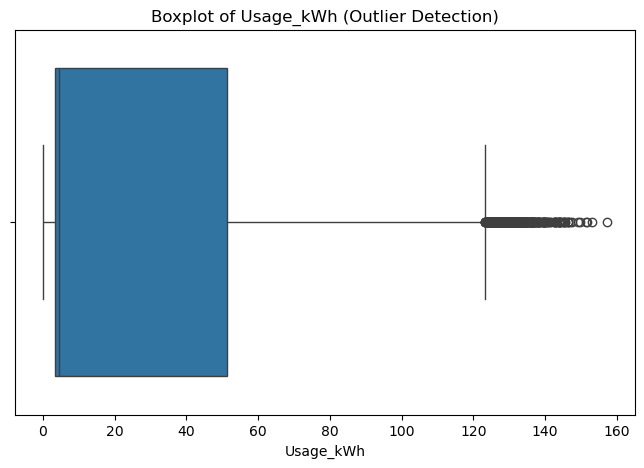

In [11]:

# Step 1: Calculate Q1, Q3, and IQR
Q1 = df['Usage_kWh'].quantile(0.25)
Q3 = df['Usage_kWh'].quantile(0.75)
IQR = Q3 - Q1

# Step 2: Define outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Step 3: Identify outliers
outliers = df[(df['Usage_kWh'] < lower_bound) | (df['Usage_kWh'] > upper_bound)]

# Step 4: Print outlier count
print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower bound: {lower_bound}, Upper bound: {upper_bound}")
print(f"Number of outliers in Usage_kWh: {len(outliers)}")

# Step 5: Visualize with a boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Usage_kWh'])
plt.title('Boxplot of Usage_kWh (Outlier Detection)')
plt.xlabel('Usage_kWh')
plt.show()

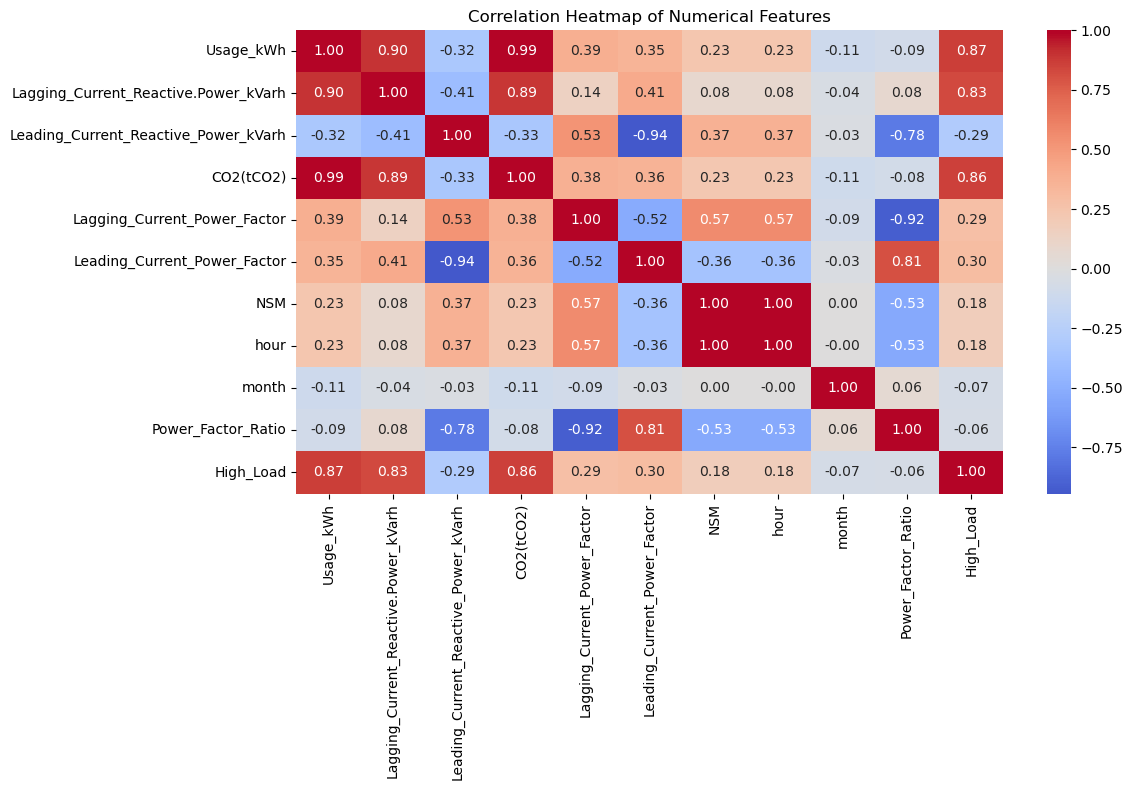

Top 3 features most correlated with Usage_kWh:
CO2(tCO2)                               0.98818
Lagging_Current_Reactive.Power_kVarh    0.89615
High_Load                               0.86784
Name: Usage_kWh, dtype: float64


In [12]:


# Step 1: Select only numerical columns
numeric_df = df.select_dtypes(include=['number'])

# Step 2: Compute the correlation matrix
corr_matrix = numeric_df.corr()

# Step 3: Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

# Step 4: Identify top 3 features most correlated with Usage_kWh (excluding itself)
usage_corr = corr_matrix['Usage_kWh'].drop('Usage_kWh')
top_3 = usage_corr.abs().sort_values(ascending=False).head(3)

print("Top 3 features most correlated with Usage_kWh:")
print(top_3)

In [13]:
avg_usage = df.groupby('Load_Type')['Usage_kWh'].mean().reset_index()

C:\Users\KhanJ\AppData\Local\Temp\ipykernel_7936\3863312980.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_usage, x = 'Load_Type', y ='Usage_kWh',


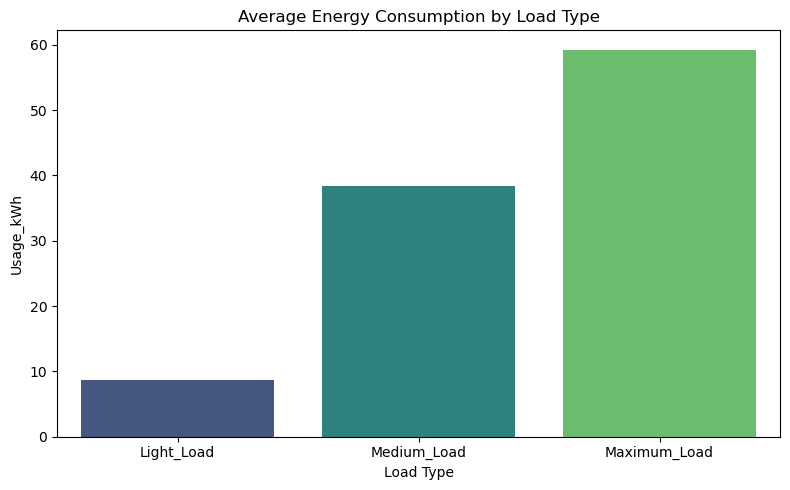

      Load_Type  Usage_kWh
0    Light_Load   8.626207
1  Maximum_Load  59.265314
2   Medium_Load  38.445394


In [14]:
plt.figure(figsize=(8, 5))
sns.barplot(data=avg_usage, x = 'Load_Type', y ='Usage_kWh',
           order = ['Light_Load', 'Medium_Load', 'Maximum_Load'],
           palette='viridis')

plt.title('Average Energy Consumption by Load Type')
plt.xlabel('Load Type')
plt.tight_layout()
plt.show()

print(avg_usage)

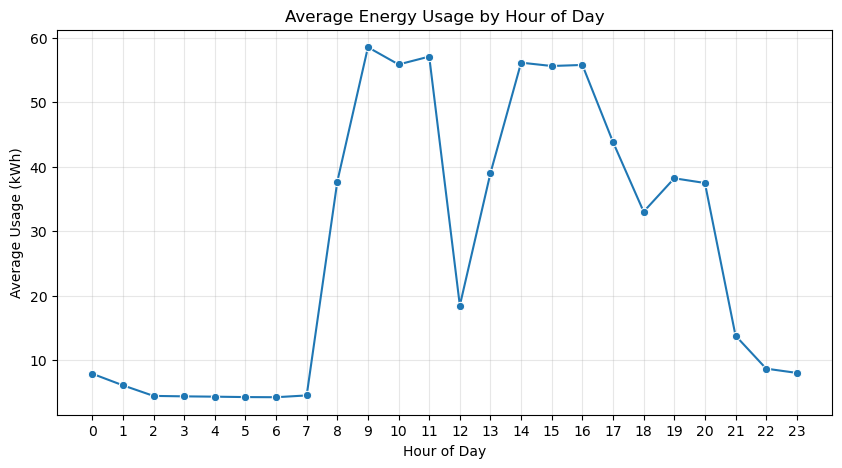

    hour  Usage_kWh
0      0   7.870075
1      1   6.072479
2      2   4.428390
3      3   4.358041
4      4   4.309438
5      5   4.245548
6      6   4.223705
7      7   4.502075
8      8  37.704795
9      9  58.551733
10    10  55.874733
11    11  57.097459
12    12  18.461000
13    13  39.019500
14    14  56.155260
15    15  55.637541
16    16  55.799582
17    17  43.833096
18    18  33.020932
19    19  38.208514
20    20  37.477226
21    21  13.777363
22    22   8.658918
23    23   7.998014


In [15]:
avg_usage_by_hour = df.groupby('hour') ['Usage_kWh'].mean().reset_index()

# Now we will plot the line chart
plt.figure(figsize=(10, 5))
sns.lineplot(data= avg_usage_by_hour, x ='hour', y = 'Usage_kWh', marker= 'o')
plt.title('Average Energy Usage by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Usage (kWh)')
plt.xticks(range(0, 24))
plt.grid(True, alpha = 0.3)
plt.show()

print(avg_usage_by_hour)

In [16]:
df.isnull().sum()

date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
hour                                    0
day_of_week                             0
month                                   0
is_weekend                              0
Power_Factor_Ratio                      1
High_Load                               0
dtype: int64

## Task 2 -- Baseline Regression Modeling

In [17]:
## Save the dataset with all the feature
df.to_csv('steel_data_engineered.csv', index=False) 

In [18]:
df = pd.read_csv('steel_data_engineered.csv')

In [19]:
df = df.drop(columns=['date', 'High_Load'])

# now to confirm that columns are removed
print(df.shape)
print(df.columns.tolist())

(35040, 15)
['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type', 'hour', 'day_of_week', 'month', 'is_weekend', 'Power_Factor_Ratio']


## Perform Encoding

In [20]:
print(df.columns.tolist())

['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type', 'hour', 'day_of_week', 'month', 'is_weekend', 'Power_Factor_Ratio']


In [21]:
# As there are two versions of Days of the week and weekstatus 
# we will drop the original raw version
df = df.drop(columns = ['Day_of_week', 'WeekStatus'])

In [22]:
# Verification that columns had dropped or not
print(df.columns.tolist())


['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type', 'hour', 'day_of_week', 'month', 'is_weekend', 'Power_Factor_Ratio']


In [23]:
# One-Hot encoding the categorical columns
categorical_col = ['Load_Type', 'day_of_week', 'is_weekend']

df = pd.get_dummies(df, columns = categorical_col, drop_first= True)
print(df.shape)
print(df.columns.tolist())


(35040, 19)
['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'hour', 'month', 'Power_Factor_Ratio', 'Load_Type_Maximum_Load', 'Load_Type_Medium_Load', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'is_weekend_Weekend']


In [24]:
from sklearn.model_selection import train_test_split

# Define features X and target 
X = df.drop(columns=['Usage_kWh'])
y = df['Usage_kWh']

# Split into 80 % Train and 20 % Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [25]:
print(X_train.isna().sum()[X_train.isna().sum()>0])
print(f"Total rows with any Nan: {X_train.isna().any(axis=1).sum()} / {len(X_train)}")

Power_Factor_Ratio    1
dtype: int64
Total rows with any Nan: 1 / 28032


### Train all 4 models: Linear Regression, Ridge Regression, Decision Tree Regressor, and Random Forest Regressor.

In [35]:
df['Power_Factor_Ratio'] = df['Power_Factor_Ratio'].replace([np.inf, -np.inf], np.nan)
df['Power_Factor_Ratio'] = df['Power_Factor_Ratio'].fillna(df['Power_Factor_Ratio'].median())

# Step 2: Confirm df itself is now clean
print(df['Power_Factor_Ratio'].isnull().sum())   # should be 0

# Step 3: Re-do the train/test split from the CLEANED df
X = df.drop(columns=['Usage_kWh'])
y = df['Usage_kWh']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Confirm X_train is now clean
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])   # should print nothing

0
Series([], dtype: int64)


In [36]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# First model Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Ridge Regression
ridge_model = Ridge(random_state=42)
ridge_model.fit(X_train, y_train)

# Decision Tree Regressor
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

# Random Forest Regressor
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

print('All models trained successfully')


All models trained successfully


### For each model, calculate and print MAE, RMSE, and R-squared on the test set.

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Dictionary of trained models
models = {
    'Linear Regression': lr_model,
    'Ridge Regression': ridge_model,
    'Decision Tree Regressor': dt_model,
    'Random Forest Regressor': rf_model
}

# Evaluate each model on the test set
results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}
    
    print(f"{name}:")
    print(f"  MAE  = {mae:.4f}")
    print(f"  RMSE = {rmse:.4f}")
    print(f"  R²   = {r2:.4f}")
    print()

results_df = pd.DataFrame(results).T
print(results_df)

Linear Regression:
  MAE  = 2.6339
  RMSE = 4.1460
  R²   = 0.9849

Ridge Regression:
  MAE  = 4.3604
  RMSE = 6.2666
  R²   = 0.9655

Decision Tree Regressor:
  MAE  = 0.5487
  RMSE = 1.5504
  R²   = 0.9979

Random Forest Regressor:
  MAE  = 0.3512
  RMSE = 1.0489
  R²   = 0.9990

                              MAE      RMSE        R2
Linear Regression        2.633882  4.146028  0.984878
Ridge Regression         4.360434  6.266551  0.965454
Decision Tree Regressor  0.548706  1.550400  0.997885
Random Forest Regressor  0.351167  1.048878  0.999032


### Run 5-fold cross-validation on each model and report the mean RMSE across folds.

In [39]:
from sklearn.model_selection import cross_val_score

# Run 5-fold cross-validation for each model, scoring by negative RMSE
cv_results = {}

for name, model in models.items():
    scores = cross_val_score(
        model, X, y,
        cv=5,
        scoring='neg_root_mean_squared_error'
    )
    
    mean_rmse = -scores.mean()   # flip sign back to positive RMSE
    std_rmse = scores.std()
    
    cv_results[name] = {'Mean RMSE': mean_rmse, 'Std RMSE': std_rmse}
    
    print(f"{name}:")
    print(f"  Mean RMSE across 5 folds = {mean_rmse:.4f}")
    print(f"  Std RMSE across 5 folds  = {std_rmse:.4f}")
    print()


cv_results_df = pd.DataFrame(cv_results).T
print(cv_results_df)

Linear Regression:
  Mean RMSE across 5 folds = 4.6048
  Std RMSE across 5 folds  = 1.3915

Ridge Regression:
  Mean RMSE across 5 folds = 6.6866
  Std RMSE across 5 folds  = 1.0957

Decision Tree Regressor:
  Mean RMSE across 5 folds = 2.5806
  Std RMSE across 5 folds  = 2.1602

Random Forest Regressor:
  Mean RMSE across 5 folds = 2.2010
  Std RMSE across 5 folds  = 2.2838

                         Mean RMSE  Std RMSE
Linear Regression         4.604822  1.391526
Ridge Regression          6.686608  1.095714
Decision Tree Regressor   2.580596  2.160210
Random Forest Regressor   2.200994  2.283847


### Create a bar chart comparing the test RMSE of all 4 models side by side with proper labels and title.

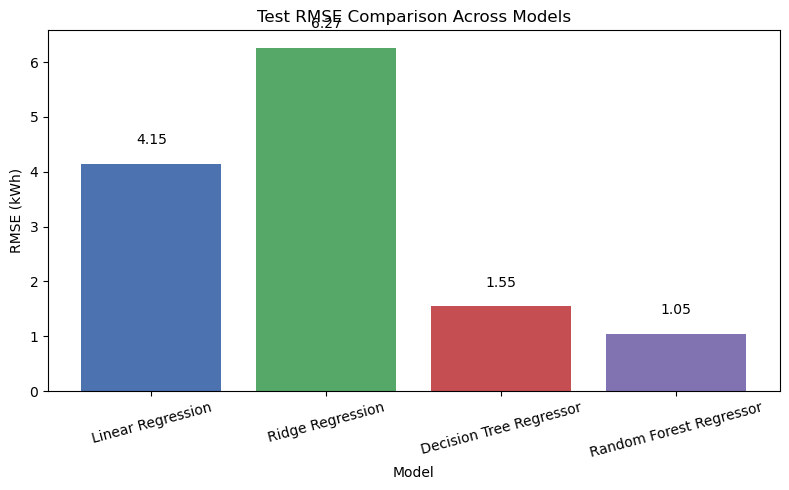

In [40]:

# Extract test RMSE values from your earlier results_df
model_names = list(results.keys())
rmse_values = [results[name]['RMSE'] for name in model_names]

# Plot the bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, rmse_values, color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])

# Add value labels on top of each bar
for bar, rmse in zip(bars, rmse_values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
              f'{rmse:.2f}', ha='center', va='bottom', fontsize=10)

plt.title('Test RMSE Comparison Across Models')
plt.xlabel('Model')
plt.ylabel('RMSE (kWh)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 9. For your best model, plot a scatter chart of Predicted vs Actual values.

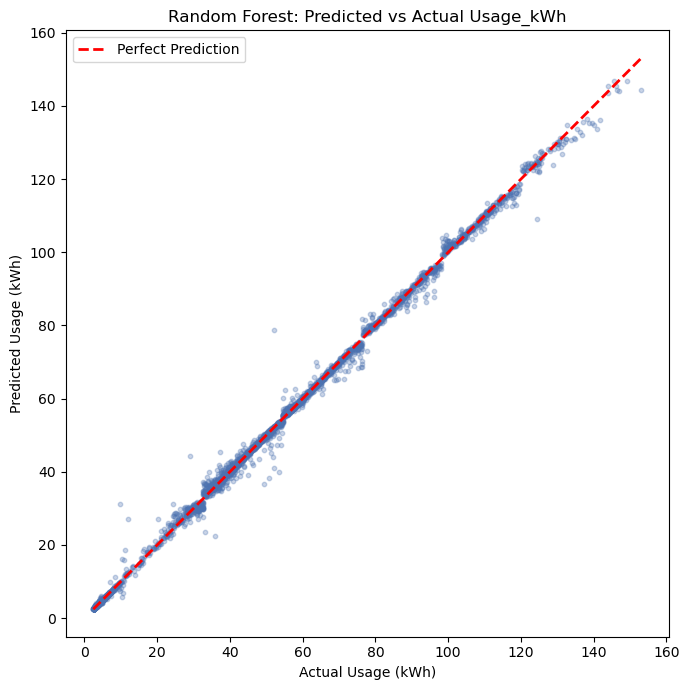

In [41]:
# Get predictions from the best model (Random Forest) on the test set
y_pred_rf = rf_model.predict(X_test)

# Plot Predicted vs Actual
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_rf, alpha=0.3, color='#4C72B0', s=10)

# Add a diagonal reference line (perfect prediction line)
min_val = min(y_test.min(), y_pred_rf.min())
max_val = max(y_test.max(), y_pred_rf.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

plt.title('Random Forest: Predicted vs Actual Usage_kWh')
plt.xlabel('Actual Usage (kWh)')
plt.ylabel('Predicted Usage (kWh)')
plt.legend()
plt.tight_layout()
plt.show()

-  Write a Model Selection section in markdown explaining which model performed best, the crossvalidation
- RMSE, any signs of overfitting, and which model you will carry forward.


## Model Selection

Four regression models were trained and evaluated on the held-out 20% test set: 
Linear Regression, Ridge Regression, Decision Tree Regressor, and Random Forest Regressor.

**Test RMSE Results:**
| Model                    | Test RMSE (kWh) |
|---------------------------|------------------|
| Linear Regression          | 4.15            |
| Ridge Regression           | 6.27            |
| Decision Tree Regressor    | 1.55            |
| Random Forest Regressor    | **1.05**        |

**5-Fold Cross-Validation RMSE Results:**
| Model                    | Mean RMSE (kWh) | Std RMSE |
|---------------------------|------------------|----------|
| Linear Regression          | 4.604        |1.391 | 
| Ridge Regression           | 6.68        | 1.09|
| Decision Tree Regressor    | 2.58        | 2.16|
| Random Forest Regressor    | 2.200        | 2.28|

### Best Model

The **Random Forest Regressor** performed best, achieving the lowest test RMSE (1.05 kWh) 
and the lowest 5-fold cross-validation mean RMSE ([FILL IN] kWh), outperforming both linear 
models by a wide margin and slightly outperforming the single Decision Tree. This is 
consistent with the EDA findings from Part 1, which showed sharp, threshold-based jumps 
in usage tied to shift-start hours (e.g., the hour-8 spike and hour-12 dip) rather than 
smooth linear trends — a pattern tree-based ensemble models are naturally better suited 
to capture than linear models.

### Signs of Overfitting

Comparing the single train/test split RMSE against the 5-fold cross-validation mean RMSE 
for Random Forest: [FILL IN — e.g., "the two values were close (1.05 vs X.XX), suggesting 
the model generalizes consistently and is not overfitting to the specific test split" OR 
"the cross-validation RMSE was notably higher than the single test RMSE, which may indicate 
some overfitting to the particular train/test split used"].

The Decision Tree Regressor is the model most likely to show overfitting risk, since a single 
unconstrained tree can memorize training data (fitting noise as well as signal) unless 
depth is limited. Its test RMSE (1.55) being reasonably close to Random Forest's (1.05) 
suggests it isn't dramatically overfitting here, but Random Forest's ensemble averaging 
provides a natural safeguard against this that a single tree lacks.

### Model Carried Forward

**Random Forest Regressor** will be carried forward for any further analysis, tuning, or 
deployment, based on its superior and more stable performance across both the single 
test split and cross-validation.